In [282]:
import time
from datetime import datetime
import json

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torchsummary import summary
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import balanced_accuracy_score, f1_score, precision_score, confusion_matrix, ConfusionMatrixDisplay

from sklearn.preprocessing import LabelEncoder

In [283]:
x_axis = 'x_maf'
y_axis = 'y_maf'
z_axis = 'z_maf'
activity_column = 'activity'

NUM_CLIENTS = 36
NUM_CLASSES = 6
SEQUENCE_LENGTH = 40
TRAINING_PERCENTAGE = 0.75
STRIDE = 10
NUM_EPOCHS = 200
PATIENCE = 10
LEARNING_RATE = 1e-4
                        #raw        #ema        #maf
THRESHOLD_1 = 0.2073    #1.0000     #0.1673     #0.2073
THRESHOLD_2 = 0.0044    #0.0187     #0.0029     #0.0044
THRESHOLD_3 = 0.0029    #0.0113     #0.0018     #0.0029
THRESHOLD_4 = 0.3644    #1.0000     #0.2785     #0.3644
THRESHOLD_5 = 0.2785    #1.0000     #0.2295     #0.2785
THRESHOLD_6 = 0.2532    #1.0000     #0.2073     #0.2532

DEVICE = torch.device("cpu") 

#np.random.seed(30)

In [284]:
def recurrence_plot_vector(data, eps):
    N = len(data)
    recurrence_matrix = np.zeros((N, N))

    # Calculate the Euclidean distance between vectors
    for i in range(N):
        for j in range(i, N):
            distance = np.linalg.norm(data[i] - data[j])
            recurrence_matrix[i, j] = recurrence_matrix[j, i] = distance

    # Apply the threshold
    recurrence_matrix = (recurrence_matrix <= eps).astype(int)
    
    return recurrence_matrix

In [285]:
def transform_to_vector_sequence(sequence):
    """
    Transform a sequence of three-channel data into a one-channel vector sequence.
    
    Parameters:
    - sequence: np.array, shape (sequence_length, 3), where 3 represents the x, y, z channels.
    
    Returns:
    - vector_sequence: list of np.array, the transformed vector sequence.
    """
    vector_sequence = [np.array([x, y, z]) for x, y, z in sequence]
    return vector_sequence

In [286]:
def transform_and_calculate_recurrence_plots(X_data):
    recurrence_plots = []
    for sequence in X_data:
        vector_sequence = transform_to_vector_sequence(sequence)

        # Generate recurrence matrices for each threshold
        rec_matrix_1 = recurrence_plot_vector(vector_sequence, THRESHOLD_1)
        rec_matrix_2 = recurrence_plot_vector(vector_sequence, THRESHOLD_2)
        rec_matrix_3 = recurrence_plot_vector(vector_sequence, THRESHOLD_3)
        rec_matrix_4 = recurrence_plot_vector(vector_sequence, THRESHOLD_4)
        if(NUM_CLASSES > 4):
            rec_matrix_5 = recurrence_plot_vector(vector_sequence, THRESHOLD_5)
            rec_matrix_6 = recurrence_plot_vector(vector_sequence, THRESHOLD_6)

        # Stack the recurrence matrices to create a multi-channel recurrence plot
        if(NUM_CLASSES == 4):
            multi_channel_rec_matrix = np.stack([rec_matrix_1, rec_matrix_2, rec_matrix_3, rec_matrix_4], axis=-1)
        else:
            multi_channel_rec_matrix = np.stack([rec_matrix_1, rec_matrix_2, rec_matrix_3, rec_matrix_4, rec_matrix_5, rec_matrix_6], axis=-1)
            
        recurrence_plots.append(multi_channel_rec_matrix)

    return recurrence_plots

# Dataset Preprocessing

In [287]:
# Function to normalize columns
def normalize_group(group):
    group[['x', 'y', 'z']] = (group[['x', 'y', 'z']] - group[['x', 'y', 'z']].mean()) / group[['x', 'y', 'z']].std()
    return group

wisdm = pd.read_csv('../../datasets/WISDM_ar_v1.1_balanced.csv', header=None, sep=',', names=['user', 'activity', 'timestamp', 'x', 'y', 'z'])

if(NUM_CLASSES == 4):
    # Filter for specific activities
    wisdm = wisdm.loc[
        (wisdm['activity'] == 'Walking') | 
        (wisdm['activity'] == 'Jogging') | 
        (wisdm['activity'] == 'Sitting') | 
        (wisdm['activity'] == 'Standing') 
    ].reset_index(drop=True)

wisdm = wisdm.groupby('user').apply(normalize_group)
wisdm = wisdm.reset_index(drop=True)
wisdm

C:\Users\tulio\AppData\Local\Temp\ipykernel_37952\115872971.py:17: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  wisdm = wisdm.groupby('user').apply(normalize_group)


,user,activity,timestamp,x,y,z
0,1,Walking,4992322339000,-0.091720,1.294345,-0.181997
1,1,Walking,4992422345000,0.390024,0.596599,-0.299797
2,1,Walking,4992722333000,1.040662,0.803481,0.175850
3,1,Walking,4993792341000,0.976051,0.650568,-0.224227
4,1,Walking,4993842298000,1.449861,0.680123,0.549256
...,...,...,...,...,...,...
290359,36,Standing,15049012250000,0.430103,0.422333,-0.155289
290360,36,Standing,15049062268000,0.330533,0.436234,-0.166769
290361,36,Standing,15049112287000,0.212525,0.439709,-0.155289
290362,36,Standing,15049162275000,0.002322,0.307651,-0.254785


In [288]:
wisdm[['x_maf', 'y_maf', 'z_maf']] = wisdm.groupby('user')[['x', 'y', 'z']].rolling(window=20).mean().reset_index(drop=True)
wisdm[['x_ema', 'y_ema', 'z_ema']] = wisdm.groupby('user')[['x', 'y', 'z']].ewm(span=30, adjust=False).mean().reset_index(drop=True)

In [289]:
def get_train_test_data_non_overlapping(wisdm, sequence_length=100, train_percentage=0.8, stride=1):
    # Get the unique users
    users = wisdm['user'].unique()
    
    # Determine the number of users to select based on the percentage
    num_train_users = int(len(users) * train_percentage)
    
    # Randomly select users for training
    train_users = np.random.choice(users, num_train_users, replace=False)
    test_users = [user for user in users if user not in train_users]

    print(f"Train Users: {train_users}")
    print(f"Test Users: {test_users}")
    
    # Split the dataset into training and test sets
    train_data = wisdm[wisdm['user'].isin(train_users)]
    test_data = wisdm[wisdm['user'].isin(test_users)]

    # Function to create sequences for each user separately
    def create_sequences(data):
        X, y = [], []
        for user in data['user'].unique():
            user_data = data[data['user'] == user]
            for i in range(0, len(user_data) - sequence_length + 1, stride):
                sequence = user_data.iloc[i:i + sequence_length]
                X.append(sequence[[x_axis, y_axis, z_axis]].values)
                y.append(sequence['activity'].iloc[-1])  # Use the last value in the sequence as the label
        return np.array(X), np.array(y)

    # Create sequences for training and test data
    X_train, y_train = create_sequences(train_data)
    X_test, y_test = create_sequences(test_data)

    return X_train, y_train, X_test, y_test

In [290]:
X_train, y_train, X_test, y_test = get_train_test_data_non_overlapping(wisdm, SEQUENCE_LENGTH, TRAINING_PERCENTAGE, STRIDE)
print(len(X_train), len(y_train), len(X_test), len(y_test))

Train Users: [22 23  5 29 26  1 18 15 34  7 11 27 19 24 14 33 30 10  9 16 36 12  2  4
 20 32 17]
Test Users: [3, 6, 8, 13, 21, 25, 28, 31, 35]
21709 21709 7202 7202


In [291]:
X_train[0].shape

(40, 3)

In [292]:
X_train_recurrence = transform_and_calculate_recurrence_plots(X_train)
X_test_recurrence = transform_and_calculate_recurrence_plots(X_test)

In [293]:
X_train_recurrence[0][:,:,0].shape

(40, 40)

In [294]:
def plot_recurrence_matrix_vector(R, title, tick_jump = 20, filename=None):
    plt.figure(figsize=(8, 8))
    
    sns.heatmap(R, cmap="binary", square=True, cbar=False)

    # Set ticks to show numbers by 5s
    tick_labels = np.arange(0, R.shape[0], tick_jump)
    plt.xticks(ticks=tick_labels + 0.5, labels=tick_labels, rotation=0)
    plt.yticks(ticks=tick_labels + 0.5, labels=tick_labels, rotation=0)

    plt.title(title)
    plt.xlabel("Sample")
    plt.ylabel("Sample")

    plt.show()  # Show the figure

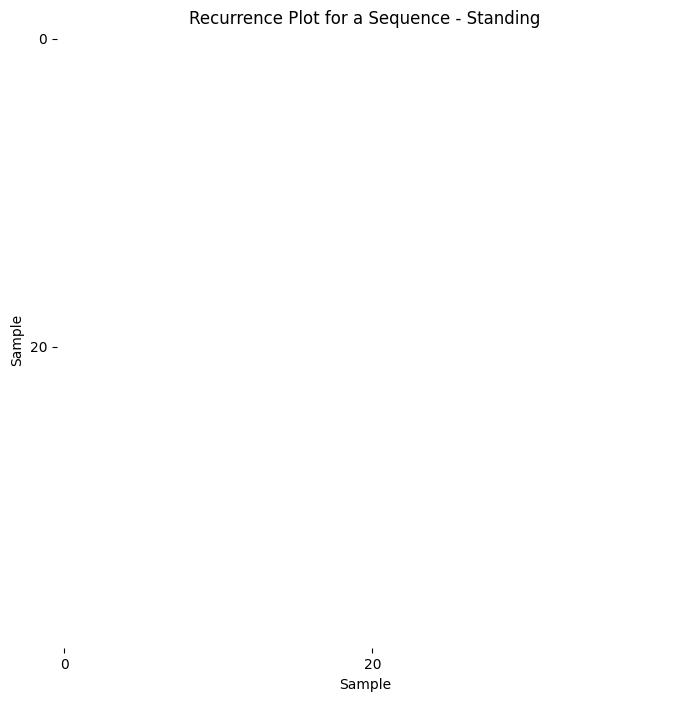

In [295]:
index = 1970
threshold_index = 3
plot_recurrence_matrix_vector(X_train_recurrence[index][:,:,threshold_index], f"Recurrence Plot for a Sequence - {y_train[index]}")

# CNN Model

In [296]:
class CNN(nn.Module):
    def __init__(self, num_classes):
        super(CNN, self).__init__()

        # Layer 1
        self.conv1 = nn.Conv2d(in_channels=NUM_CLASSES, out_channels=16, kernel_size=5, stride=1, padding=0) # (4, 40, 40) -> (16, 36, 36)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)  # (16, 36, 36) -> (16, 18, 18)

        # Layer 2
        self.conv2 = nn.Conv2d(in_channels=16, out_channels=32, kernel_size=5, stride=1, padding=0)  # (16, 18, 18) -> (32, 14, 14)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)  # (32, 14, 14) -> (32, 7, 7)

        # Layer 3
        self.conv3 = nn.Conv2d(in_channels=32, out_channels=64, kernel_size=3, stride=1, padding=0)  # (32, 7, 7) -> (64, 5, 5)
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2, padding=0)  # (64, 5, 5) -> (64, 2, 2)

        # Layer 4
        self.conv4 = nn.Conv2d(in_channels=64, out_channels=128, kernel_size=2, stride=1, padding=0)  # (64, 2, 2) -> (128, 1, 1)

        # Fully Connected layers
        self.fc1 = nn.Linear(128 * 1 * 1, 256)  # Adjust based on the output of conv layers
        self.fc2 = nn.Linear(256, num_classes)   # Output layer

    def forward(self, x):
        x = self.pool1(F.relu(self.conv1(x)))  # Convolution, ReLU, and pooling
        x = self.pool2(F.relu(self.conv2(x)))  # Convolution, ReLU, and pooling
        x = self.pool3(F.relu(self.conv3(x)))  # Convolution, ReLU, and pooling
        x = F.relu(self.conv4(x))               # Last convolution, no pooling here

        # Flatten the tensor
        x = x.view(-1, 128 * 1 * 1)  # Adjust based on the output size
        x = F.relu(self.fc1(x))       # First fully connected layer
        x = self.fc2(x)               # Output layer
        return x

In [297]:
def evaluate(loader, model):
    """
    Evaluate the model on the given dataset.

    Parameters:
    - loader: DataLoader containing the evaluation dataset.
    - model: Trained PyTorch model.

    Returns:
    - balanced_acc: Balanced accuracy of the model.
    - f1: F1 score of the model.
    - precision: Precision of the model.
    - conf_matrix: Normalized confusion matrix.
    """
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for x_batch, y_batch in loader:
            data, labels = x_batch.to(DEVICE), y_batch.to(DEVICE)
            outputs = model(data)
            _, predicted = torch.max(outputs.data, 1)
            all_preds.extend(predicted.cpu().numpy())  # Transform to numpy to add to the full list of predictions
            all_labels.extend(labels.cpu().numpy())

    balanced_acc = balanced_accuracy_score(all_labels, all_preds) * 100
    f1 = f1_score(all_labels, all_preds, average='weighted') * 100
    precision = precision_score(all_labels, all_preds, average='weighted', zero_division=0) * 100
    conf_matrix = confusion_matrix(all_labels, all_preds, normalize='true')

    return balanced_acc, f1, precision, conf_matrix

In [298]:
def train(model, train_loader, test_loader, criterion, optimizer, num_epochs, patience=5, verbose=False):
    """
    Train the model with early stopping and evaluate it at each epoch.

    Parameters:
    - model: PyTorch model to be trained.
    - train_loader: DataLoader object containing the training data.
    - test_loader: DataLoader object containing the test data.
    - criterion: Loss function.
    - optimizer: Optimization algorithm.
    - num_epochs: Number of epochs to train the model.
    - patience: Number of epochs to wait before early stopping if no improvement.
    - verbose: Boolean indicating whether to print detailed information during training.

    Returns:
    - train_losses: List of training losses for each epoch.
    - train_metrics: Dictionary containing training metrics (accuracy, F1 score, precision, confusion matrix).
    - test_metrics: Dictionary containing test metrics (accuracy, F1 score, precision, confusion matrix).
    """
    total_training_time = 0
    best_test_acc = 0
    epochs_no_improve = 0
    train_metrics = {'accuracy': [], 'f1score': [], 'precision': [], 'conf_matrix': None}
    test_metrics = {'accuracy': [], 'f1score': [], 'precision': [], 'conf_matrix': None}
    train_losses = []

    for epoch in range(num_epochs):
        model.train()
        start_epoch_time = time.time()
        total_loss = 0

        for x_batch, y_batch in train_loader:
            data, labels = x_batch.to(DEVICE), y_batch.to(DEVICE)
            optimizer.zero_grad()
            outputs = model(data)
            # Print shapes for debugging
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader)
        end_epoch_time = time.time()
        epoch_time = end_epoch_time - start_epoch_time
        total_training_time += epoch_time
        train_losses.append(avg_loss)

        # Evaluate on training and test data
        train_acc, train_f1, train_precision, train_conf_matrix = evaluate(train_loader, model)
        test_acc, test_f1, test_precision, test_conf_matrix = evaluate(test_loader, model)

        # Store the metrics
        train_metrics['accuracy'].append(train_acc)
        train_metrics['f1score'].append(train_f1)
        train_metrics['precision'].append(train_precision)
        test_metrics['accuracy'].append(test_acc)
        test_metrics['f1score'].append(test_f1)
        test_metrics['precision'].append(test_precision)

        # Check for the best accuracy and update early stopping criteria
        if test_acc > best_test_acc:
            best_test_acc = test_acc
            train_metrics['conf_matrix'] = train_conf_matrix
            test_metrics['conf_matrix'] = test_conf_matrix
            epochs_no_improve = 0
        else:
            epochs_no_improve += 1

        if verbose:
            print(f'Epoch [{epoch+1}/{num_epochs}], Train Loss: {avg_loss:.4f}, Train Accuracy: {train_acc:.2f}%, '
                  f'Test Accuracy: {test_acc:.2f}%, Time: {epoch_time:.2f} seconds')

        # Early stopping
        if epochs_no_improve == patience:
            print(f'Early stopping at epoch {epoch+1} with best test accuracy: {best_test_acc:.2f}%')
            break

    if verbose:
        print(f'Total Training Time: {total_training_time:.2f} seconds')

    return train_losses, train_metrics, test_metrics

In [299]:
# Encode labels to integers
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(y_train)
labels_names = list(label_encoder.classes_)
y_test = label_encoder.transform(y_test)

# Convert X_train and y_train to tensors
X_train_tensor = torch.tensor(X_train_recurrence, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)

X_test_tensor = torch.tensor(X_test_recurrence, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.long)

# Reshape the input tensor to have the shape (batch_size, channels, height, width)
X_train_tensor = X_train_tensor.permute(0, 3, 1, 2)  # Change from (batch_size, 40, 40, 4) to (batch_size, 4, 40, 40)
X_test_tensor = X_test_tensor.permute(0, 3, 1, 2)    # Same for test data

# Create DataLoader for training and testing data
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, drop_last=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False, drop_last=True)

In [300]:
labels_names

['Downstairs', 'Jogging', 'Sitting', 'Standing', 'Upstairs', 'Walking']

In [301]:
first_loader = next(iter(train_loader))
first_loader[0].shape

torch.Size([32, 6, 40, 40])

In [302]:
# Instantiate the model, loss function, and optimizer
model = CNN(NUM_CLASSES)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)

In [303]:
summary(model, (NUM_CLASSES, 40, 40))

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 16, 36, 36]           2,416
         MaxPool2d-2           [-1, 16, 18, 18]               0
            Conv2d-3           [-1, 32, 14, 14]          12,832
         MaxPool2d-4             [-1, 32, 7, 7]               0
            Conv2d-5             [-1, 64, 5, 5]          18,496
         MaxPool2d-6             [-1, 64, 2, 2]               0
            Conv2d-7            [-1, 128, 1, 1]          32,896
            Linear-8                  [-1, 256]          33,024
            Linear-9                    [-1, 6]           1,542
Total params: 101,206
Trainable params: 101,206
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.04
Forward/backward pass size (MB): 0.27
Params size (MB): 0.39
Estimated Total Size (MB): 0.70
-------------------------------------------

In [304]:
# Assuming that `model`, `train_loader`, `test_loader`, `criterion`, and `optimizer` are already defined

train_losses, train_metrics, test_metrics = train(
    model=model,
    train_loader=train_loader,
    test_loader=test_loader,
    criterion=criterion,
    optimizer=optimizer,
    num_epochs=NUM_EPOCHS,
    patience=PATIENCE,
    verbose=True
)

print("Training complete.")

Epoch [1/200], Train Loss: 1.1672, Train Accuracy: 53.48%, Test Accuracy: 51.87%, Time: 9.46 seconds
Epoch [2/200], Train Loss: 1.0087, Train Accuracy: 53.15%, Test Accuracy: 52.35%, Time: 9.62 seconds
Epoch [3/200], Train Loss: 0.9833, Train Accuracy: 54.44%, Test Accuracy: 50.70%, Time: 9.56 seconds
Epoch [4/200], Train Loss: 0.9679, Train Accuracy: 54.81%, Test Accuracy: 50.50%, Time: 9.76 seconds
Epoch [5/200], Train Loss: 0.9611, Train Accuracy: 56.05%, Test Accuracy: 51.92%, Time: 9.77 seconds
Epoch [6/200], Train Loss: 0.9506, Train Accuracy: 54.90%, Test Accuracy: 49.95%, Time: 9.80 seconds
Epoch [7/200], Train Loss: 0.9479, Train Accuracy: 55.27%, Test Accuracy: 53.59%, Time: 10.51 seconds
Epoch [8/200], Train Loss: 0.9384, Train Accuracy: 57.29%, Test Accuracy: 54.95%, Time: 10.57 seconds
Epoch [9/200], Train Loss: 0.9346, Train Accuracy: 56.35%, Test Accuracy: 52.67%, Time: 9.92 seconds
Epoch [10/200], Train Loss: 0.9274, Train Accuracy: 56.59%, Test Accuracy: 54.28%, Time: 

In [305]:
print(f"Best Test Accuracy: {test_metrics['accuracy'][-PATIENCE-1]:.2f}%")
print(f"Best Test F1 Score: {test_metrics['f1score'][-PATIENCE-1]:.2f}%")
print(f"Best Test Precision: {test_metrics['precision'][-PATIENCE-1]:.2f}%")

Best Test Accuracy: 59.97%
Best Test F1 Score: 55.70%
Best Test Precision: 60.49%


In [306]:
# Prepare data to save
if(NUM_CLASSES == 4):
    metrics_data = {
        'constants': {
            'AXIS': [x_axis, y_axis, z_axis],
            'NUM_CLIENTS': NUM_CLIENTS,
            'TRAINING_PERCENTAGE': TRAINING_PERCENTAGE,
            'NUM_CLASSES': NUM_CLASSES,
            'SEQUENCE_LENGTH': SEQUENCE_LENGTH,
            'STRIDE': STRIDE,
            'PATIENCE': PATIENCE,
            'LEARNING_RATE': LEARNING_RATE,
            'THRESHOLDS': [THRESHOLD_1, THRESHOLD_2, THRESHOLD_3, THRESHOLD_4],
            'LABEL_NAMES': labels_names,
            'BEST_ACCURACY': test_metrics['accuracy'][-PATIENCE-1],
            'BEST_F1': test_metrics['f1score'][-PATIENCE-1],
            'BEST_PRECISION': test_metrics['precision'][-PATIENCE-1]
        },
        'train_losses': train_losses,
        'train_metrics': train_metrics,
        'test_metrics': test_metrics
    }
else:
    metrics_data = {
        'constants': {
            'AXIS': [x_axis, y_axis, z_axis],
            'NUM_CLIENTS': NUM_CLIENTS,
            'TRAINING_PERCENTAGE': TRAINING_PERCENTAGE,
            'NUM_CLASSES': NUM_CLASSES,
            'SEQUENCE_LENGTH': SEQUENCE_LENGTH,
            'STRIDE': STRIDE,
            'PATIENCE': PATIENCE,
            'LEARNING_RATE': LEARNING_RATE,
            'THRESHOLDS': [THRESHOLD_1, THRESHOLD_2, THRESHOLD_3, THRESHOLD_4, THRESHOLD_5, THRESHOLD_6],
            'LABEL_NAMES': labels_names,
            'BEST_ACCURACY': test_metrics['accuracy'][-PATIENCE-1],
            'BEST_F1': test_metrics['f1score'][-PATIENCE-1],
            'BEST_PRECISION': test_metrics['precision'][-PATIENCE-1]
        },
        'train_losses': train_losses,
        'train_metrics': train_metrics,
        'test_metrics': test_metrics
    }


In [307]:
def convert_to_serializable(data):
    if isinstance(data, np.ndarray):
        return data.tolist()  # Convert NumPy array to list
    if isinstance(data, dict):
        return {key: convert_to_serializable(value) for key, value in data.items()}
    if isinstance(data, list):
        return [convert_to_serializable(item) for item in data]
    return data  # Return the data as is if it's not a NumPy array or a dict/list

In [308]:
# Generate a datetime string for the filename
datetime_str = datetime.now().strftime("%Y%m%d_%H%M%S")

# Save to JSON file
filename = f'../../results/recurrence_cnn_wisdm_training_metrics_{datetime_str}.json'
with open(filename, 'w') as f:
    json.dump(convert_to_serializable(metrics_data), f, indent=4)

In [309]:
def plot_metrics(train, test, title, metric):
    # summarize history for accuracy
    plt.plot(train)
    plt.plot(test)
    plt.grid()
    plt.title(title)
    plt.ylabel(metric)
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='best')
    plt.show()

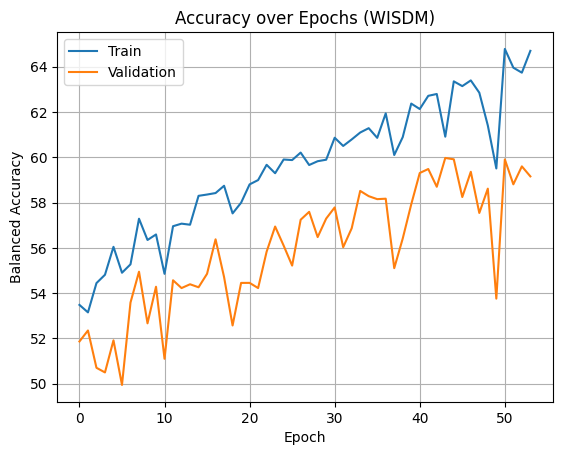

In [310]:
plot_metrics(train_metrics['accuracy'], test_metrics['accuracy'], 'Accuracy over Epochs (WISDM)', 'Balanced Accuracy')

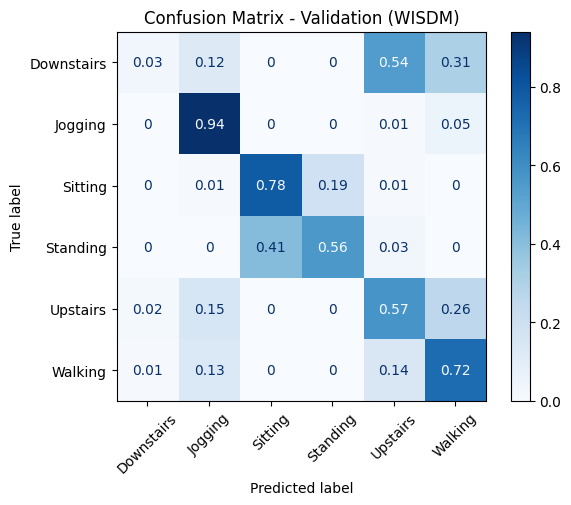

In [311]:
disp = ConfusionMatrixDisplay(confusion_matrix=test_metrics['conf_matrix'].round(2), display_labels=labels_names)
disp.plot(cmap='Blues')
plt.title('Confusion Matrix - Validation (WISDM)')
plt.xticks(rotation=45)
plt.show()